# Forecasting: 54 products

In [1]:
from pathlib import Path
import json,hashlib,time,inspect,platform
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import rankdata
from numba import njit
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display,Markdown

ROOT=Path.cwd(); INPUT=ROOT/'artifacts/research_54/statistics/manifest.json'; manifest=json.loads(INPUT.read_text())
OUT=ROOT/'artifacts/research_54/models'
for p in [OUT,OUT/'by_file',OUT/'forecasts',OUT/'figures']: p.mkdir(parents=True,exist_ok=True)
files=manifest['files']; assert len(files)==54
SPLIT=pd.Timestamp('2020-01-01'); INNER=pd.Timestamp('2019-01-01')
MIN_TRAIN_DAYS=20; MIN_DIRECTION_ROWS=1000; EGARCH_SIMULATIONS=2048; RANDOM_SEED=42
EXPANSION_WINDOW=30; EXPANSION_MIN_PERIODS=15; BREAKOUT_WINDOW=20
VOLATILITY_NAMES=['V1_GARCH','V2_EGARCH','V3_GJR_GARCH']
ARMA_CANDIDATES=[(1,0),(2,0),(1,1)]
MEAN_ORDERS={'AR(1)':(1,0),'MA(1)':(0,1),'AR(2)':(2,0),'ARMA(1,1)':(1,1)}
MEAN_HORIZONS=[1,2,3,5]; VAR_HORIZONS=[1,5,30]
DIRECTION_NAMES=['D0_Momentum5','D1_Raw_ARMA','D2_GARCH_ARMA','D2_EGARCH_ARMA','D2_GJR_ARMA','D3_Logistic_Core','D3_Logistic_Asymmetric']
REUSE_VERIFIED_CACHE=True
def digest(path):
    with Path(path).open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
input_hash=digest(INPUT)
def json_safe(value):
    if isinstance(value,dict): return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [json_safe(v) for v in value]
    if isinstance(value,np.ndarray): return json_safe(value.tolist())
    if isinstance(value,(np.integer,np.floating,np.bool_)): return json_safe(value.item())
    if isinstance(value,float) and not np.isfinite(value): return None
    if isinstance(value,(pd.Timestamp,np.datetime64)): return str(value)
    return value
def show(df,title,rows=15):
    display(df.head(rows).style.hide(axis='index').format(precision=5,na_rep='NA').set_caption(title))
    if len(df)>rows: print(f"""Showing {rows}/{len(df)} rows; the complete table is in CSV.""")
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':120})
def savefig(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight'); plt.show()

## Variance recursions

In [2]:
@njit
def wf_variance_kernel(x, reset, parameters, kind, gradient=False):
    # kind 0: symmetric GARCH, 1: EGARCH, 2: GJR with positive/negative shock loadings.
    n = len(x)
    variance = np.full(n, np.nan)
    derivatives = np.zeros(4)
    grad = np.zeros(4)
    hprev = 1.0
    uprev = 0.0
    active = False
    loss = 0.0
    count = 0
    clipped = 0
    for i in range(n):
        if not np.isfinite(x[i]):
            active = False
            continue
        fresh = reset[i] or not active
        if fresh:
            h = 1.0
            derivatives[:] = 0.0
        elif kind == 1:
            omega, alpha, beta, gamma = parameters
            z = uprev / np.sqrt(hprev)
            log_previous = np.log(hprev)
            log_h = omega + beta*log_previous + alpha*(abs(z)-np.sqrt(2/np.pi)) + gamma*z
            propagation = beta - 0.5*z*(alpha*np.sign(z)+gamma)
            derivatives *= propagation
            derivatives[0] += 1.0
            derivatives[1] += abs(z)-np.sqrt(2/np.pi)
            derivatives[2] += log_previous
            derivatives[3] += z
            if log_h < -30 or log_h > 30:
                log_h = max(-30.0, min(30.0, log_h)); derivatives[:] = 0.0; clipped += 1
            h = np.exp(log_h)
        else:
            omega, positive, negative, beta = parameters
            shock_coefficient = positive if uprev >= 0 else negative
            h = omega + shock_coefficient*uprev*uprev + beta*hprev
            derivatives *= beta
            derivatives[0] += 1.0
            derivatives[1 if uprev >= 0 else 2] += uprev*uprev
            derivatives[3] += hprev
        variance[i] = h
        if not fresh:
            loss += 0.5*(np.log(h) + x[i]*x[i]/h)
            score = 0.5*(1.0-x[i]*x[i]/h) if kind == 1 else 0.5*(1/h-x[i]*x[i]/(h*h))
            grad += score*derivatives
            count += 1
        uprev, hprev, active = x[i], h, True
    return variance, loss/max(count, 1), grad/max(count, 1), count, clipped

def wf_gjr_transform(raw):
    omega = np.exp(raw[0])
    weights = np.exp(np.r_[0.0, raw[1:]]-max(0.0, *raw[1:]))
    shares = weights/weights.sum()
    loads = .999*shares[1:]
    p = np.array([omega, 2*loads[0], 2*loads[1], loads[2]])
    jac = np.zeros((4, 4)); jac[0, 0] = omega
    for i in range(3):
        for j in range(3):
            jac[i+1, j+1] = p[i+1]*((i == j)-shares[j+1])
    return p, jac

def wf_gjr_objective(raw, x, reset):
    physical, jac = wf_gjr_transform(raw)
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, physical, 2)
    return loss, derivative @ jac

def wf_egarch_objective(parameters, x, reset):
    _, loss, derivative, _, _ = wf_variance_kernel(x, reset, parameters, 1)
    return loss, derivative

def wf_egarch_factors(fit, horizon, rng):
    # Common random numbers factorize the Gaussian EGARCH log-variance recursion.
    omega, alpha, beta, gamma = fit["parameters"]
    if not isinstance(horizon, (int, np.integer)) or isinstance(horizon, (bool, np.bool_)) or horizon < 1:
        raise ValueError("horizon must be a positive integer")
    if EGARCH_SIMULATIONS < 2 or EGARCH_SIMULATIONS % 2:
        raise ValueError("EGARCH_SIMULATIONS must be positive and even")
    # Preserve the original fixed-horizon Gaussian Monte Carlo experiment.
    normal = rng.standard_normal((EGARCH_SIMULATIONS//2, horizon))
    normal = np.concatenate([normal, -normal], axis=0)
    offsets = np.zeros(len(normal))
    factors, powers = [1.0], [1.0]
    for j in range(1, horizon):
        z = normal[:, j-1]
        offsets = omega + beta*offsets + alpha*(np.abs(z)-np.sqrt(2/np.pi)) + gamma*z
        factors.append(float(np.exp(np.clip(offsets, -60, 60)).mean()))
        powers.append(beta**j)
    return np.asarray(factors), np.asarray(powers)

def wf_volatility_forecasts(values, segments, fit, horizon, rng):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    variance, _, _, _, clipped = wf_variance_kernel(x, reset, fit["parameters"], fit["kind"])
    z = x/np.sqrt(variance)
    if fit["kind"] == 1:
        omega, alpha, beta, gamma = fit["parameters"]
        next_log = omega+beta*np.log(variance)+alpha*(np.abs(z)-np.sqrt(2/np.pi))+gamma*z
        next_log = np.clip(next_log, -30, 30)
        factors, powers = wf_egarch_factors(fit, horizon, rng)
        forecasts = np.exp(next_log[:, None]*powers[None, :])*factors[None, :]
        contribution = gamma*z
    else:
        omega, positive, negative, beta = fit["parameters"]
        next_variance = omega + np.where(x < 0, negative, positive)*x*x + beta*variance
        forecasts = np.empty((len(values), horizon)); forecasts[:, 0] = next_variance
        for j in range(1, horizon):
            forecasts[:, j] = omega+fit["persistence"]*forecasts[:, j-1]
        contribution = (negative-positive)*np.where(x < 0, x*x, 0.0)/np.maximum(next_variance, 1e-12)
    return variance*fit["scale"]**2, forecasts*fit["scale"]**2, z, contribution, clipped

In [3]:
def garch_parameters(unconstrained):
    omega = np.exp(unconstrained[0])
    weights = np.exp(np.r_[0.0, unconstrained[1:]] - max(0.0, *unconstrained[1:]))
    shares = weights / weights.sum()
    alpha, beta = 0.999 * shares[1:]
    jacobian = np.array([[omega, 0.0, 0.0],
                        [0.0, alpha * (1-shares[1]), -alpha * shares[2]],
                        [0.0, -beta * shares[1], beta * (1-shares[2])]])
    return omega, alpha, beta, jacobian

## Estimation

In [4]:
def model_garch_objective(raw,x,reset):
    omega,alpha,beta,jac=garch_parameters(raw)
    _,loss,grad,_,_=wf_variance_kernel(x,reset,np.array([omega,alpha,alpha,beta]),0)
    return loss,np.array([grad[0],grad[1]+grad[2],grad[3]])@jac

def model_fit_volatility(values,segments,model):
    values = np.asarray(values, dtype=float); segments = np.asarray(segments)
    if values.ndim != 1 or segments.ndim != 1 or len(values) != len(segments):
        raise ValueError("values and segments must be aligned one-dimensional arrays")
    finite = np.isfinite(values)
    if finite.sum() < MIN_DIRECTION_ROWS: return None
    location = float(np.mean(values[finite])); scale = float(np.std(values[finite]))
    if not np.isfinite(scale) or scale <= 0: return None
    x=(values-location)/scale; reset=np.r_[True,segments[1:]!=segments[:-1]]
    effective = finite & ~reset & np.r_[False, finite[:-1]]
    if not effective.any(): return None
    if model=='V1_GARCH':
        starts=[]
        for omega,alpha,beta in [(.05,.1,.85),(.2,.2,.6),(.05,.4,.55)]:
            rem=.999-alpha-beta; starts.append(np.array([np.log(omega),np.log(alpha/rem),np.log(beta/rem)]))
        objective=model_garch_objective; bounds=[(-18,5),(-12,12),(-12,12)]; kind=0
    elif model=='V2_EGARCH':
        starts=[np.array([-.02,.15,.90,0.]),np.array([-.1,.3,.75,-.1])]
        objective=wf_egarch_objective; bounds=[(-5,2),(0,2),(0,.999),(-2,2)]; kind=1
    else:
        starts=[np.array([np.log(.05),np.log(.05/.049),np.log(.05/.049),np.log(.85/.049)]),np.array([np.log(.2),0.,.5,1.])]
        objective=wf_gjr_objective; bounds=[(-18,5),(-12,12),(-12,12),(-12,12)]; kind=2
    attempts=[minimize(objective,start,args=(x,reset),jac=True,method='L-BFGS-B',bounds=bounds,
                      options={'maxiter':250,'ftol':1e-10,'gtol':1e-6}) for start in starts]
    good=[r for r in attempts if r.success and np.isfinite(r.fun)]
    if not good: return None
    best=min(good,key=lambda r:r.fun)
    if kind==0:
        omega,alpha,beta,_=garch_parameters(best.x); parameters=np.array([omega,alpha,alpha,beta])
    elif kind==1: parameters=best.x
    else: parameters,_=wf_gjr_transform(best.x)
    _,loss,_,count,hits=wf_variance_kernel(x,reset,parameters,kind)
    if kind==1: omega,alpha,beta,gamma=parameters; persistence=beta
    else: omega,alpha,negative,beta=parameters; gamma=negative-alpha; persistence=beta+.5*(alpha+negative)
    k=len(best.x)+1; loglik=-count*(loss+.5*np.log(2*np.pi)+np.log(scale))
    boundary=any(abs(v-lo)<1e-4 or abs(v-hi)<1e-4 for v,(lo,hi) in zip(best.x,bounds)) or persistence>.998
    return dict(parameters=parameters,kind=kind,location=location,scale=scale,omega=omega,alpha=alpha,beta=beta,gamma=gamma,persistence=persistence,
        loss=loss,loglik=loglik,aic=2*k-2*loglik,bic=k*np.log(count)-2*loglik,n=int(count),success=True,
        attempts=len(attempts),successful_attempts=len(good),optimizer_message=str(best.message),iterations=int(best.nit),boundary=bool(boundary),numerical_bound_hits=int(hits))

## Direction models

In [5]:
@njit
def wf_arma_kernel(values, reset, phi1, phi2, theta):
    residual = np.full(len(values), np.nan)
    age, previous, previous2, error = 0, 0.0, 0.0, 0.0
    total, count = 0.0, 0
    for i in range(len(values)):
        if not np.isfinite(values[i]): age = 0; continue
        if reset[i]: age = 0
        current_error = values[i]-phi1*previous-phi2*previous2-theta*error if age >= 2 else 0.0
        residual[i] = current_error
        if age >= 2: total += current_error*current_error; count += 1
        previous2, previous, error = previous, values[i], current_error
        age += 1
    return residual, total/max(count, 1), count

def wf_ar_forecast(values, segments, fit, horizon):
    x = (values-fit["location"])/fit["scale"]
    reset = np.r_[True, segments[1:] != segments[:-1]]
    residual, _, _ = wf_arma_kernel(x, reset, fit["phi1"], fit["phi2"], fit["theta"])
    previous = np.r_[np.nan, x[:-1]]
    previous[reset] = np.nan
    next_value = fit["phi1"]*x+fit["phi2"]*np.nan_to_num(previous, nan=0.0)+fit["theta"]*residual
    outputs = np.empty((len(values), horizon)); outputs[:, 0] = next_value
    last, second = next_value, x.copy()
    for j in range(1, horizon):
        current = fit["phi1"]*last+fit["phi2"]*second
        outputs[:, j] = current; second, last = last, current
    return fit["location"] + fit["scale"]*outputs

In [6]:
def model_ar_parameters(parameters,order):
    if order==(2,0): return parameters[0]*(1-parameters[1]),parameters[1],0.
    if order==(1,1): return parameters[0],0.,parameters[1]
    if order==(0,1): return 0.,0.,parameters[0]
    return parameters[0],0.,0.

def model_ar_loss(parameters,x,reset,order):
    return wf_arma_kernel(x,reset,*model_ar_parameters(parameters,order))[1]

def model_fit_ar(values,segments,order=None):
    finite=np.isfinite(values)
    if finite.sum()<MIN_DIRECTION_ROWS: return None
    location=float(np.mean(values[finite])); scale=float(np.std(values[finite]))
    if not scale>0: return None
    x=(values-location)/scale; reset=np.r_[True,segments[1:]!=segments[:-1]]
    fits=[]
    for specification in ARMA_CANDIDATES if order is None else [tuple(order)]:
        dim=sum(specification); starts=[np.zeros(dim),np.full(dim,-.15)]
        attempts=[minimize(model_ar_loss,start,args=(x,reset,specification),method='L-BFGS-B',bounds=[(-.98,.98)]*dim,
                           options={'maxiter':180,'ftol':1e-11,'gtol':1e-7}) for start in starts]
        good=[r for r in attempts if r.success and np.isfinite(r.fun) and r.fun>0]
        if not good: continue
        best=min(good,key=lambda r:r.fun); phi1,phi2,theta=model_ar_parameters(best.x,specification)
        _,mse,n=wf_arma_kernel(x,reset,phi1,phi2,theta)
        loglik=-.5*n*(np.log(2*np.pi)+1+np.log(mse*scale*scale)); k=dim+2
        fits.append(dict(order=specification,phi1=phi1,phi2=phi2,theta=theta,location=location,scale=scale,n=int(n),mse=mse,
            aic=2*k-2*loglik,bic=k*np.log(n)-2*loglik,success=True,boundary=bool((np.abs(best.x)>.9799).any()),
            near_cancellation=bool(specification==(1,1) and abs(phi1+theta)<.02),iterations=int(best.nit),optimizer_message=str(best.message)))
    return min(fits,key=lambda f:(f['bic'],f['order'])) if fits else None

In [7]:
LOGIT_BASE_FEATURES = ["r0", "r1", "r2", "momentum5", "std_garch", "previous_sign",
    "logvol_garch", "change_garch", "expansion_garch", "innovation_garch"]
LOGIT_ASYM_FEATURES = LOGIT_BASE_FEATURES + ["logvol_egarch", "logvol_gjr", "change_egarch", "change_gjr",
    "egarch_contribution", "gjr_contribution", "difference_egarch", "difference_gjr"]

def wf_fit_logistic(features, target):
    valid = np.isfinite(features).all(axis=1) & np.isfinite(target)
    x, y = features[valid], target[valid]
    if len(y) < MIN_DIRECTION_ROWS or len(np.unique(y)) < 2: return None
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale = np.where(scale > 1e-12, scale, 1.0)
    x = (x-center)/scale
    # Fixed L2 strength; no holdout tuning or class rebalancing.
    def objective(coef):
        linear = coef[0]+x@coef[1:]
        loss = np.mean(np.logaddexp(0, linear)-y*linear)+.0005*np.sum(coef[1:]**2)
        error = expit(linear)-y
        derivative = np.r_[error.mean(), x.T@error/len(y)+.001*coef[1:]]
        return loss, derivative
    fit = minimize(objective, np.zeros(x.shape[1]+1), jac=True, method="L-BFGS-B", options={"maxiter": 150, "ftol": 1e-10})
    if not fit.success: return None
    return dict(coefficients=fit.x, center=center, scale=scale, n=len(y), success=True)

def wf_predict_logistic(features, fit):
    return expit(fit["coefficients"][0] + ((features-fit["center"])/fit["scale"])@fit["coefficients"][1:])

In [8]:
def wf_features(data, volatility):
    result = pd.DataFrame(index=data.index)
    groups = data.groupby("segment_id", sort=False)
    for lag in [0, 1, 2]: result[f"r{lag}"] = groups.log_return.shift(lag)
    result["momentum5"] = groups.log_return.transform(lambda s: s.rolling(5, min_periods=5).sum())
    result["previous_sign"] = np.sign(data.log_return)
    for model, short in zip(VOLATILITY_NAMES, ["garch", "egarch", "gjr"]):
        sigma = np.sqrt(volatility[f"variance_H_{model}"])
        result[f"logvol_{short}"] = np.log(sigma.where(sigma > 0))
        result[f"change_{short}"] = result[f"logvol_{short}"].groupby(data.segment_id).diff()
        median = sigma.groupby(data.segment_id).transform(lambda s: s.shift(1).rolling(EXPANSION_WINDOW,
            min_periods=EXPANSION_MIN_PERIODS).median())
        result[f"expansion_{short}"] = sigma/median
        result[f"std_{short}"] = data.log_return/np.sqrt(volatility[f"current_variance_{model}"])
    result["innovation_garch"] = volatility["innovation_V1_GARCH"]
    result["egarch_contribution"] = volatility["contribution_V2_EGARCH"]
    result["gjr_contribution"] = volatility["contribution_V3_GJR_GARCH"]
    result["difference_egarch"] = result.logvol_egarch-result.logvol_garch
    result["difference_gjr"] = result.logvol_gjr-result.logvol_garch
    upper = groups.High.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).max())
    lower = groups.Low.transform(lambda s: s.shift(1).rolling(BREAKOUT_WINDOW, min_periods=BREAKOUT_WINDOW).min())
    result["breakout"] = np.where(data.Close > upper, 1.0, np.where(data.Close < lower, -1.0, 0.0))
    result.loc[upper.isna() | lower.isna(), "breakout"] = np.nan
    return result.replace([np.inf, -np.inf], np.nan)

## Targets and losses

In [9]:
def model_targets(frame,horizon,delay=0,location=0.):
    n=len(frame); d=horizon+delay; ids=frame.segment_id.to_numpy(); r=frame.log_return.to_numpy(); close=frame.close.to_numpy()
    response=np.full(n,np.nan); variance=np.full(n,np.nan)
    if n<=d: return response,variance
    ix=np.arange(n-d); valid=ids[ix]==ids[ix+d]; total=np.zeros(len(ix))
    for k in range(1,d+1):
        valid&=np.isfinite(r[ix+k])
        if k>delay: total+=(r[ix+k]-location)**2
    valid&=(close[ix+delay]>0)&(close[ix+d]>0)&np.isfinite(close[ix+delay])&np.isfinite(close[ix+d])
    use=ix[valid]; response[use]=np.log(close[use+d]/close[use+delay]); variance[use]=total[valid]/horizon
    return response,variance

@njit
def model_ewma(values,reset,location,scale):
    out=np.full(len(values),np.nan); h=1.; active=False
    for i in range(len(values)):
        if not np.isfinite(values[i]): active=False; continue
        if reset[i] or not active: h=1.
        x=(values[i]-location)/scale; h=.94*h+.06*x*x; out[i]=h*scale*scale; active=True
    return out

def model_corr(x,y):
    return float(np.corrcoef(x,y)[0,1]) if len(x)>1 and np.ptp(x)>0 and np.ptp(y)>0 else np.nan

def model_direction_metrics(target,score,probability=None,baseline_probability=None):
    y=(target>0).astype(float); active=(target!=0)&(score!=0); up=y==1; down=y==0
    result=dict(n=len(y),zero_share=float(np.mean(target==0)),direction_coverage=float(np.mean(score!=0)),
        sign_n=int(active.sum()),sign_accuracy=float(np.mean(np.sign(target[active])==np.sign(score[active]))) if active.any() else np.nan,
        binary_accuracy=float(np.mean((score>0)==up)),balanced_accuracy=.5*(np.mean(score[up]>0)+np.mean(score[down]<=0)) if up.any() and down.any() else np.nan,
        target_correlation=model_corr(target,score),auc=np.nan,brier=np.nan,brier_skill_train_frequency=np.nan)
    if probability is not None:
        result['brier']=float(np.mean((probability-y)**2))
        if up.any() and down.any():
            ranks=rankdata(probability); result['auc']=float((ranks[up].sum()-up.sum()*(up.sum()+1)/2)/(up.sum()*down.sum()))
        if baseline_probability is not None:
            baseline=np.mean((baseline_probability-y)**2); result['brier_skill_train_frequency']=1-result['brier']/baseline if baseline>0 else np.nan
    return result

def model_vol_predictions(values,segments,fit,horizon,seed):
    current,future,z,contribution,hits=wf_volatility_forecasts(values,segments,fit,horizon,np.random.default_rng(seed))
    if fit['kind']==1:
        p=fit['parameters']; x=(values-fit['location'])/fit['scale']
        standardized=current/fit['scale']**2
        log_next=p[0]+p[2]*np.log(standardized)+p[1]*(np.abs(z)-np.sqrt(2/np.pi))+p[3]*z
        next_hits=int(np.sum((log_next< -30)|(log_next>30)))
    else: next_hits=0
    return current,future,z,contribution,dict(filter_guard_hits=int(hits),next_guard_hits=next_hits,nonfinite_forecasts=int((~np.isfinite(future[np.isfinite(values)])).sum()))

## Recursion checks

In [10]:
probe=pd.read_parquet(ROOT/manifest['features'][0]['path']).iloc[:6000]
r=probe.log_return.to_numpy(); seg=probe.segment_id.to_numpy(); reset=np.r_[True,seg[1:]!=seg[:-1]]
mu=np.nanmean(r); sd=np.nanstd(r); x=(r-mu)/sd
for objective,point in [(model_garch_objective,np.array([np.log(.05),0.,2.])),(wf_gjr_objective,np.array([np.log(.05),0.,.3,2.])),
                        (wf_egarch_objective,np.array([-.02,.15,.9,-.08]))]:
    _,gradient=objective(point,x,reset); numerical=[]
    for j in range(len(point)):
        step=np.zeros(len(point)); step[j]=1e-5
        numerical.append((objective(point+step,x,reset)[0]-objective(point-step,x,reset)[0])/2e-5)
    np.testing.assert_allclose(gradient,numerical,rtol=3e-4,atol=3e-5)
for kind,p in [(0,np.array([.05,.1,.1,.85])),(1,np.array([-.02,.15,.9,-.08])),(2,np.array([.05,.08,.16,.82]))]:
    fit=dict(kind=kind,parameters=p,location=mu,scale=sd,persistence=p[2] if kind==1 else p[3]+.5*(p[1]+p[2]))
    before=model_vol_predictions(r,seg,fit,6,42)[1]
    changed=r.copy(); changed[4000:]+=sd*10
    after=model_vol_predictions(changed,seg,fit,6,42)[1]
    np.testing.assert_allclose(before[:4000],after[:4000],equal_nan=True,atol=1e-14)
for h in [1,5,30]:
    target,var=model_targets(probe,h,location=mu)
    for i in np.flatnonzero(np.isfinite(target))[:8]:
        assert seg[i]==seg[i+h]
        np.testing.assert_allclose(target[i],np.log(probe.close.iloc[i+h]/probe.close.iloc[i]),atol=1e-14)
        np.testing.assert_allclose(var[i],np.mean((r[i+1:i+h+1]-mu)**2),rtol=1e-12)
print("GARCH/GJR/EGARCH gradients, prefix causality and future targets checked.")
# Independent scalar ARMA recursion and fixed-parameter forecast prefix check.
phi1,phi2,theta=-.1,.05,.15
reference=np.full(len(x),np.nan); age=0; previous=previous2=error=0.
for i,value in enumerate(x):
    if not np.isfinite(value): age=0; continue
    if reset[i]: age=0
    current=value-phi1*previous-phi2*previous2-theta*error if age>=2 else 0.
    reference[i]=current
    previous2,previous,error=previous,value,current; age+=1
np.testing.assert_allclose(wf_arma_kernel(x,reset,phi1,phi2,theta)[0],reference,equal_nan=True,atol=1e-12)
check_fit=dict(location=mu,scale=sd,phi1=phi1,phi2=phi2,theta=theta)
changed=r.copy(); changed[4000:]+=10*sd
np.testing.assert_allclose(wf_ar_forecast(r,seg,check_fit,6)[:4000],wf_ar_forecast(changed,seg,check_fit,6)[:4000],equal_nan=True,atol=1e-14)
print("Independent ARMA scalar recursion and prefix causality checked.")


GARCH/GJR/EGARCH gradients, prefix causality and future targets checked.
Independent ARMA scalar recursion and prefix causality checked.


## Run by instrument

In [11]:
def model_process_file(record,number):
    filename=record['file']; frame=pd.read_parquet(ROOT/record['path'])
    values=frame.log_return.to_numpy(); segments=frame.segment_id.to_numpy(); reset=np.r_[True,segments[1:]!=segments[:-1]]
    train=(frame.date<SPLIT).to_numpy(); inner=(frame.date<INNER).to_numpy(); stage2=(frame.date.ge(INNER)&frame.date.lt(SPLIT)).to_numpy()
    test=~train; minute=(frame.date.dt.hour*60+frame.date.dt.minute).to_numpy(); grid=minute%6==0
    fit_rows=[]; mean_rows=[]; variance_rows=[]; direction_rows=[]; calibration_rows=[]; regime_rows=[]; numeric_rows=[]
    training=values[train&np.isfinite(values)]; ndays=frame.loc[train&np.isfinite(values),'date'].dt.normalize().nunique()
    coverage=dict(file=filename,train_returns=len(training),train_dates=int(ndays),test_rows=int(test.sum()),
        inner_train_dates=int(frame.loc[inner&np.isfinite(values),'date'].dt.normalize().nunique()),
        stage2_dates=int(frame.loc[stage2&np.isfinite(values),'date'].dt.normalize().nunique()),status='eligible')
    if len(training)<MIN_DIRECTION_ROWS or ndays<MIN_TRAIN_DAYS or np.std(training)<=0:
        coverage['status']='insufficient_train_dates_returns_or_variance'
        return {'coverage':[coverage],'fits':[],'mean':[],'variance':[],'direction':[],'calibration':[],'regimes':[],'numerics':[]}
    location=float(training.mean()); scale=float(training.std()); floor=1e-8*scale*scale
    selected=test&grid; pred=frame.loc[selected,['date','ID','symbol','segment_id','log_return','volume']].copy().reset_index(drop=True)
    fits={name:model_fit_ar(values[train],segments[train],order) for name,order in MEAN_ORDERS.items()}
    fitted={name:fit for name,fit in fits.items() if fit is not None}
    for name,fit in fits.items(): fit_rows.append(dict(file=filename,stage='full_train',model=name,train_end='2019-12-31',**(fit or {'success':False})))
    forecast_means={name:wf_ar_forecast(values,segments,fit,6) for name,fit in fitted.items()}
    for horizon in MEAN_HORIZONS:
        target,_=model_targets(frame,horizon)
        predictions={'Zero':np.zeros(len(frame)),'Training mean':np.full(len(frame),horizon*location)}
        predictions.update({name:p[:,:horizon].sum(axis=1) for name,p in forecast_means.items()})
        common=selected&np.isfinite(target)&np.isfinite(values)
        for p in predictions.values(): common &= np.isfinite(p)
        pred[f'mean_target_h{horizon}']=target[selected]; pred[f'mean_common_h{horizon}']=common[selected]
        for name,p in predictions.items():
            pred[f'mean_{name}_h{horizon}']=p[selected]
            for period,mask in [('test',common),('2020',common&(frame.date.dt.year.to_numpy()==2020)),('2021',common&(frame.date.dt.year.to_numpy()==2021))]:
                y=target[mask]; z=p[mask]
                if not len(y): continue
                mse=np.mean((y-z)**2); denominator=np.mean(y*y); sign=(y!=0)&(z!=0)
                mean_rows.append(dict(file=filename,period=period,model=name,horizon=horizon,n=len(y),mse=mse,mae=np.mean(np.abs(y-z)),
                    mse_skill_zero=1-mse/denominator if denominator>0 else np.nan,sign_n=int(sign.sum()),
                    sign_accuracy=np.mean(np.sign(y[sign])==np.sign(z[sign])) if sign.any() else np.nan,
                    zero_share=np.mean(y==0),correlation=model_corr(y,z)))
    variance_predictions={h:{'Historical':np.full(len(frame),scale*scale),'Trailing30':frame.rolling_30m_volatility.to_numpy()**2,
                             'EWMA':model_ewma(values,reset,location,scale)} for h in VAR_HORIZONS}
    for j,name in enumerate(VOLATILITY_NAMES):
        fit=model_fit_volatility(values[train],segments[train],name)
        fit_rows.append(dict(file=filename,stage='full_train',model=name,train_end='2019-12-31',**(fit or {'success':False})))
        if fit is None: continue
        current,future,z,contribution,numeric=model_vol_predictions(values,segments,fit,max(VAR_HORIZONS),RANDOM_SEED+number*100+j)
        numeric_rows.append(dict(file=filename,stage='full_train',model=name,**numeric))
        for horizon in VAR_HORIZONS: variance_predictions[horizon][name]=future[:,:horizon].mean(axis=1)
    for horizon in VAR_HORIZONS:
        _,target=model_targets(frame,horizon,location=location); predictions=variance_predictions[horizon]
        common=selected&np.isfinite(target)&np.isfinite(values)
        for p in predictions.values(): common &= np.isfinite(p)&(p>=0)
        pred[f'variance_target_h{horizon}']=target[selected]; pred[f'variance_common_h{horizon}']=common[selected]
        for name,p in predictions.items():
            pred[f'variance_{name}_h{horizon}']=p[selected]
            for period,mask in [('test',common),('2020',common&(frame.date.dt.year.to_numpy()==2020)),('2021',common&(frame.date.dt.year.to_numpy()==2021))]:
                y=target[mask]; raw=p[mask]; z=np.maximum(raw,floor); baseline=np.maximum(predictions['EWMA'][mask],floor)
                if not len(y): continue
                loss=np.log(z)+y/z; diff=loss-(np.log(baseline)+y/baseline)
                variance_rows.append(dict(file=filename,period=period,model=name,horizon=horizon,n=len(y),qlike=loss.mean(),qlike_delta_ewma=diff.mean(),
                    mse=np.mean((y-z)**2),volatility_rmse=np.sqrt(np.mean((np.sqrt(y)-np.sqrt(z))**2)),
                    volatility_correlation=model_corr(np.sqrt(y),np.sqrt(z)),floor_count=int((raw<floor).sum()),
                    realized_to_forecast=y.mean()/z.mean(),min_forecast=raw.min(),max_forecast=raw.max()))
    # Inner split: feature model fit strictly before 2019, direction model fit only on settled 2019 labels.
    volatility=pd.DataFrame(index=frame.index)
    for name in VOLATILITY_NAMES:
        for prefix in ['current_variance','variance_H','innovation','contribution']: volatility[f'{prefix}_{name}']=np.nan
    inner_ok=coverage['inner_train_dates']>=MIN_TRAIN_DAYS and np.isfinite(values[inner]).sum()>=MIN_DIRECTION_ROWS
    if inner_ok:
        for j,name in enumerate(VOLATILITY_NAMES):
            fit=model_fit_volatility(values[inner],segments[inner],name)
            fit_rows.append(dict(file=filename,stage='inner_2016_2018',model=name,train_end='2018-12-31',**(fit or {'success':False})))
            if fit is None: continue
            current,future,z,contribution,numeric=model_vol_predictions(values,segments,fit,6,RANDOM_SEED+number*100+j+50)
            for prefix,column in [('current_variance',current),('variance_H',future[:,1:6].sum(axis=1)),('innovation',z),('contribution',contribution)]:
                volatility[f'{prefix}_{name}']=column
            numeric_rows.append(dict(file=filename,stage='inner_2016_2018',model=name,**numeric))
    features=wf_features(frame.rename(columns={'close':'Close','high':'High','low':'Low'}),volatility)
    target,_=model_targets(frame,5,delay=1)
    predictions={name:np.full(len(frame),np.nan) for name in DIRECTION_NAMES}
    predictions['D0_Momentum5']=np.sign(features.momentum5.to_numpy())
    candidates=[f for f in fitted.values() if tuple(f['order']) in ARMA_CANDIDATES]
    chosen=min(candidates,key=lambda f:(f['bic'],f['order'])) if candidates else None
    if chosen is not None: predictions['D1_Raw_ARMA']=wf_ar_forecast(values,segments,chosen,6)[:,1:6].sum(axis=1)
    coverage['raw_arma_order']=str(chosen['order']) if chosen else 'unavailable'
    for name,short in zip(DIRECTION_NAMES[2:5],['garch','egarch','gjr']):
        standardized=features[f'std_{short}'].to_numpy()
        fit=model_fit_ar(standardized[stage2],segments[stage2]) if inner_ok and coverage['stage2_dates']>=MIN_TRAIN_DAYS else None
        fit_rows.append(dict(file=filename,stage='direction_2019',model=name,train_end='2019-12-31',**(fit or {'success':False})))
        if fit is not None: predictions[name]=wf_ar_forecast(standardized,segments,fit,6)[:,1:6].sum(axis=1)
    baseline_probs={}
    settled=frame.date.to_numpy()+np.timedelta64(6,'m')<np.datetime64(SPLIT)
    for name,columns in [('D3_Logistic_Core',LOGIT_BASE_FEATURES),('D3_Logistic_Asymmetric',LOGIT_ASYM_FEATURES)]:
        y=np.where(np.isfinite(target),(target>0).astype(float),np.nan)
        X=features[columns].to_numpy(); available=stage2&grid&settled&np.isfinite(y)&np.isfinite(X).all(axis=1)
        fit=wf_fit_logistic(X[available],y[available]) if inner_ok and coverage['stage2_dates']>=MIN_TRAIN_DAYS else None
        fit_rows.append(dict(file=filename,stage='direction_2019',model=name,train_end='2019-12-31',features=columns,**(fit or {'success':False})))
        if fit is not None:
            predictions[name]=wf_predict_logistic(X,fit); baseline_probs[name]=float(y[available].mean())
    common=selected&np.isfinite(target)
    for p in predictions.values(): common &= np.isfinite(p)
    coverage['common_direction_origins']=int(common.sum()); coverage['direction_models_available']=sum(np.isfinite(p[selected]).any() for p in predictions.values())
    coverage['inner_status']='eligible' if inner_ok else 'insufficient_pre2019_history'
    pred['direction_target_h5_delay1']=target[selected]; pred['direction_common']=common[selected]
    for name,p in predictions.items():
        pred[name]=p[selected]; available=selected&np.isfinite(target)&np.isfinite(p)
        for cohort,mask in [('available',available),('common_all7',common)]:
            for period,choose in [('test',mask),('2020',mask&(frame.date.dt.year.to_numpy()==2020)),('2021',mask&(frame.date.dt.year.to_numpy()==2021))]:
                if not choose.any(): continue
                probabilistic=name.startswith('D3'); probability=p[choose] if probabilistic else None; score=2*p[choose]-1 if probabilistic else p[choose]
                direction_rows.append(dict(file=filename,period=period,model=name,cohort=cohort,
                    **model_direction_metrics(target[choose],score,probability,baseline_probs.get(name))))
            if name.startswith('D3') and mask.any():
                probability=p[mask]; y=(target[mask]>0).astype(float); buckets=np.minimum((probability*10).astype(int),9)
                for bucket in range(10):
                    k=buckets==bucket
                    if k.any(): calibration_rows.append(dict(file=filename,model=name,cohort=cohort,bucket=bucket,n=int(k.sum()),sum_probability=probability[k].sum(),positive_count=int(y[k].sum())))
    # Breakout + expansion: classification-only diagnostic on the same base origins, no positions.
    for short in ['garch','egarch','gjr']:
        expansion=features[f'expansion_{short}'].to_numpy(); signal=features.breakout.to_numpy()
        base=selected&np.isfinite(target)&np.isfinite(signal)&(signal!=0)&np.isfinite(expansion)
        for regime,mask in [('all_breakouts',base),('expansion_ge_1.2',base&(expansion>=1.2)),('expansion_lt_1.2',base&(expansion<1.2))]:
            if mask.any(): regime_rows.append(dict(file=filename,model=short,regime=regime,**model_direction_metrics(target[mask],signal[mask])))
    path=OUT/'forecasts'/(Path(filename).stem+'.parquet'); pred.to_parquet(path,index=False,compression='zstd')
    coverage['forecast_rows']=len(pred); coverage['forecast_sha256']=digest(path)
    return dict(coverage=[coverage],fits=fit_rows,mean=mean_rows,variance=variance_rows,direction=direction_rows,
                calibration=calibration_rows,regimes=regime_rows,numerics=numeric_rows)

In [12]:
# Include every computation function in the cache fingerprint, including copied Numba kernels.
functions=[value for name,value in list(globals().items()) if name.startswith(('model_','wf_','garch_parameters')) and callable(value)]
code_hash=hashlib.sha256('\n'.join(inspect.getsource(getattr(f,'py_func',f)) for f in functions).encode()).hexdigest()
config=dict(split=str(SPLIT),inner=str(INNER),min_days=MIN_TRAIN_DAYS,min_rows=MIN_DIRECTION_ROWS,seed=RANDOM_SEED,
    egarch_simulations=EGARCH_SIMULATIONS,mean_horizons=MEAN_HORIZONS,var_horizons=VAR_HORIZONS,grid_minutes=6,
    direction_features=[LOGIT_BASE_FEATURES,LOGIT_ASYM_FEATURES],code_hash=code_hash,backtest=False,
    runtime_constants=dict(expansion_window=EXPANSION_WINDOW,expansion_min_periods=EXPANSION_MIN_PERIODS,
        breakout_window=BREAKOUT_WINDOW,arma_candidates=ARMA_CANDIDATES,mean_orders=MEAN_ORDERS,
        volatility_names=VOLATILITY_NAMES,direction_names=DIRECTION_NAMES))
parts={key:[] for key in ['coverage','fits','mean','variance','direction','calibration','regimes','numerics']}
started=time.monotonic()
with threadpool_limits(limits=1):
    for number,record in enumerate(manifest['features'],1):
        path=ROOT/record['path']; assert digest(path)==record['sha256']
        fingerprint=hashlib.sha256(json.dumps(dict(config=config,record=record),sort_keys=True).encode()).hexdigest()
        cache=OUT/'by_file'/(Path(record['file']).stem+'.json')
        stored=json.loads(cache.read_text()) if cache.exists() and REUSE_VERIFIED_CACHE else None
        forecast=OUT/'forecasts'/(Path(record['file']).stem+'.parquet')
        valid_cache=stored is not None and stored.get('fingerprint')==fingerprint
        if valid_cache:
            cov=stored['results']['coverage'][0]
            if cov.get('forecast_sha256'): valid_cache=forecast.exists() and digest(forecast)==cov['forecast_sha256']
        if valid_cache: result=stored['results']; source='cache'
        else:
            result=model_process_file(record,number); source='fit'
            cache.write_text(json.dumps(json_safe(dict(fingerprint=fingerprint,results=result)),ensure_ascii=False,indent=2)+'\n')
        # Canonical full-precision containers in both fresh-fit and cache paths.
        result=json_safe(result)
        for key,value in result.items(): parts[key].extend(value)
        if number%9==0 or result['coverage'][0]['status']!='eligible': print(f"""{number:02}/54 {record["file"]}: {source}; {result["coverage"][0]["status"]}; {time.monotonic()-started:.0f} s""",flush=True)
tables={key:pd.DataFrame(value) for key,value in parts.items()}
for key,table in tables.items(): table.to_csv(OUT/(key+'.csv'),index=False)
coverage=tables['coverage']; fits=tables['fits']; means=tables['mean']; variance=tables['variance']; directions=tables['direction']; calibration=tables['calibration']; regimes=tables['regimes']; numerics=tables['numerics']
assert set(coverage.file)==set(files) and len(coverage)==54
print("Forecasts and metrics saved; all 54 requested files, including ineligible files, are accounted for.")

09/54 CU9999.XSGE.csv: fit; eligible; 61 s


18/54 MA9999.XZCE.csv: fit; eligible; 125 s


27/54 IH9999.CCFX.csv: fit; eligible; 180 s


32/54 SA9999.XZCE.csv: fit; insufficient_train_dates_returns_or_variance; 201 s


36/54 SP9999.XSGE.csv: fit; eligible; 226 s


45/54 SN9999.XSGE.csv: fit; eligible; 271 s


54/54 RR9999.XDCE.csv: fit; eligible; 308 s


Forecasts and metrics saved; all 54 requested files, including ineligible files, are accounted for.


## Forecast results

In [13]:
show(coverage[['file','train_dates','inner_train_dates','stage2_dates','status','direction_models_available','common_direction_origins']], "Coverage of every requested file",54)
fit_summary=fits.groupby(['stage','model'],sort=False).agg(requested=('file','nunique'),successful=('success','sum')).reset_index()
show(fit_summary,"Optimization and calibration results",30)
mean_summary=means.groupby(['period','model','horizon']).agg(files=('file','nunique'),n=('n','sum'),mean_skill=('mse_skill_zero','mean'),median_skill=('mse_skill_zero','median'),
    better_files=('mse_skill_zero',lambda s:(s>0).sum()),median_sign_accuracy=('sign_accuracy','median')).reset_index()
variance_summary=variance.groupby(['period','model','horizon']).agg(files=('file','nunique'),n=('n','sum'),median_qlike_delta_ewma=('qlike_delta_ewma','median'),
    mean_qlike_delta_ewma=('qlike_delta_ewma','mean'),better_files=('qlike_delta_ewma',lambda s:(s<0).sum()),
    median_vol_corr=('volatility_correlation','median'),floor_count=('floor_count','sum')).reset_index()
direction_summary=directions.groupby(['period','cohort','model']).agg(files=('file','nunique'),n=('n','sum'),accuracy=('binary_accuracy','mean'),
    balanced_accuracy=('balanced_accuracy','mean'),sign_accuracy=('sign_accuracy','mean'),zero_share=('zero_share','mean'),direction_coverage=('direction_coverage','mean'),
    auc=('auc','mean'),brier_skill=('brier_skill_train_frequency','mean')).reset_index()
for name,table in [('mean_summary',mean_summary),('variance_summary',variance_summary),('direction_summary',direction_summary)]: table.to_csv(OUT/(name+'.csv'),index=False)
show(mean_summary.query('period=="test" and horizon==1'),"One-minute forecast: MSE skill against zero",8)
show(variance_summary.query('period=="test" and horizon==5'),"Five-minute variance: QLIKE against EWMA",8)
show(direction_summary.query('period=="test" and cohort=="common_all7"'),"Direction: common cohort, equal-file mean",8)

file,train_dates,inner_train_dates,stage2_dates,status,direction_models_available,common_direction_origins
RB9999.XSGE.csv,988,744,244,eligible,7.00000,18165.00000
I9999.XDCE.csv,975,731,244,eligible,7.00000,18165.00000
SC9999.XINE.csv,513,224,289,eligible,7.00000,30660.00000
NI9999.XSGE.csv,1152,863,289,eligible,7.00000,25305.00000
J9999.XDCE.csv,975,731,244,eligible,7.00000,18165.00000
RU9999.XSGE.csv,975,731,244,eligible,7.00000,18165.00000
IF9999.CCFX.csv,975,731,244,eligible,7.00000,14688.00000
AU9999.XSGE.csv,1152,863,289,eligible,7.00000,30660.00000
CU9999.XSGE.csv,1152,863,289,eligible,7.00000,25305.00000
AG9999.XSGE.csv,1152,863,289,eligible,7.00000,30660.00000


stage,model,requested,successful
full_train,AR(1),53,53
full_train,MA(1),53,53
full_train,AR(2),53,53
full_train,"ARMA(1,1)",53,53
full_train,V1_GARCH,53,53
full_train,V2_EGARCH,53,53
full_train,V3_GJR_GARCH,53,53
inner_2016_2018,V1_GARCH,46,46
inner_2016_2018,V2_EGARCH,46,46
inner_2016_2018,V3_GJR_GARCH,46,46


period,model,horizon,files,n,mean_skill,median_skill,better_files,median_sign_accuracy
test,AR(1),1,53,1184763,0.00689,0.00636,45,0.55577
test,AR(2),1,53,1184763,0.00684,0.00617,43,0.56041
test,"ARMA(1,1)",1,53,1184763,0.00686,0.00607,44,0.56074
test,MA(1),1,53,1184763,0.00690,0.00608,44,0.56079
test,Training mean,1,53,1184763,-0.00000,0.00000,27,0.50041
test,Zero,1,53,1184763,0.00000,0.00000,0,NA


period,model,horizon,files,n,median_qlike_delta_ewma,mean_qlike_delta_ewma,better_files,median_vol_corr,floor_count
test,EWMA,5,53,755545,0.00000,0.00000,0,0.56750,0
test,Historical,5,53,755545,0.25559,0.30474,0,NA,0
test,Trailing30,5,53,755545,3.55781,23032.84272,0,0.54006,1667
test,V1_GARCH,5,53,755545,0.00218,0.01016,21,0.55833,0
test,V2_EGARCH,5,53,755545,0.00816,0.03921,11,0.54579,0
test,V3_GJR_GARCH,5,53,755545,0.00223,0.01018,23,0.55794,0


period,cohort,model,files,n,accuracy,balanced_accuracy,sign_accuracy,zero_share,direction_coverage,auc,brier_skill
test,common_all7,D0_Momentum5,46,877286,0.49480,0.48691,0.48039,0.11483,0.88596,NA,NA
test,common_all7,D1_Raw_ARMA,46,877286,0.52277,0.50065,0.50063,0.11483,1.00000,NA,NA
test,common_all7,D2_EGARCH_ARMA,46,877286,0.52169,0.50540,0.50686,0.11483,1.00000,NA,NA
test,common_all7,D2_GARCH_ARMA,46,877286,0.51754,0.50549,0.50742,0.11483,1.00000,NA,NA
test,common_all7,D2_GJR_ARMA,46,877286,0.52045,0.50501,0.50684,0.11483,1.00000,NA,NA
test,common_all7,D3_Logistic_Asymmetric,46,877286,0.55537,0.51001,0.50504,0.11483,1.00000,0.52901,0.00499
test,common_all7,D3_Logistic_Core,46,877286,0.55539,0.50910,0.50402,0.11483,1.00000,0.52896,0.00431


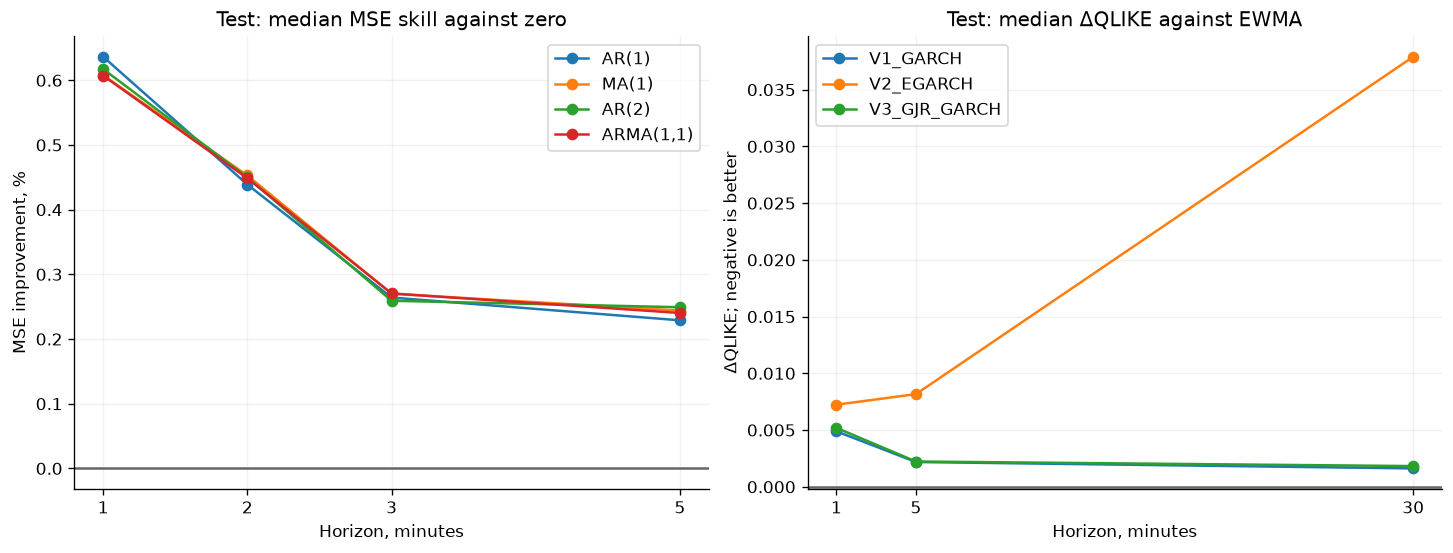

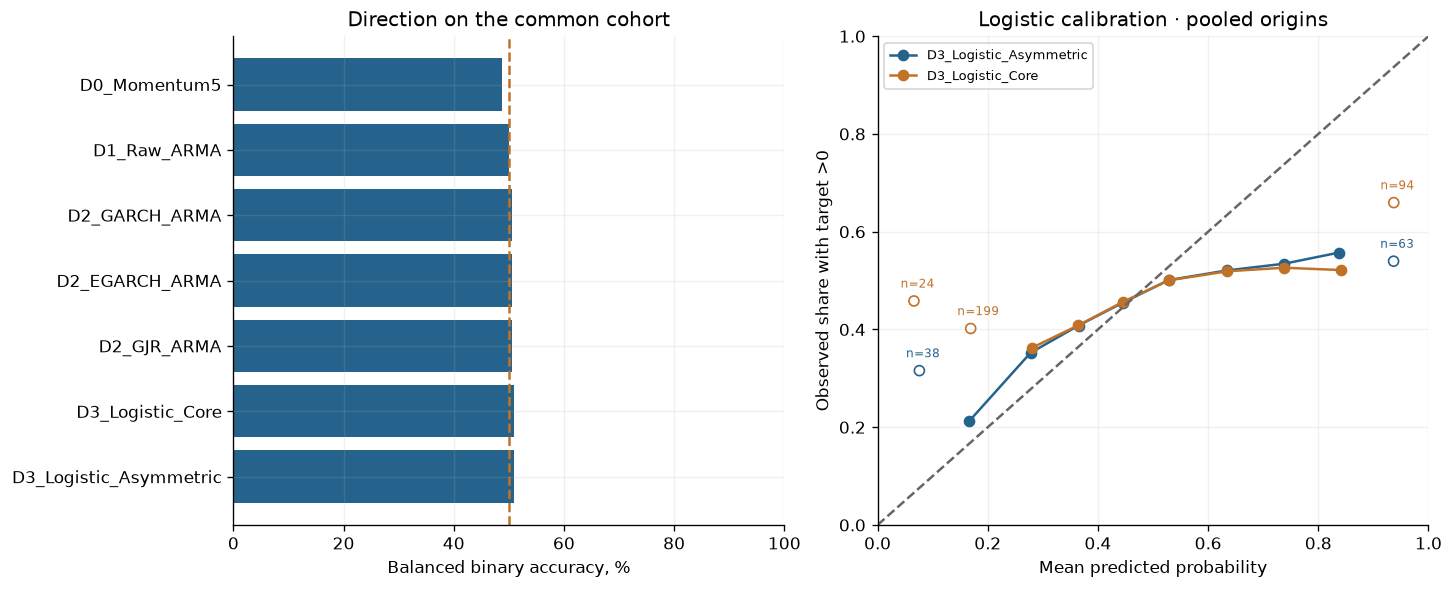

In [14]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for name in MEAN_ORDERS:
    p=mean_summary.query('period=="test" and model==@name').sort_values('horizon')
    axes[0].plot(p.horizon,100*p.median_skill,'o-',label=name)
axes[0].set_xticks(MEAN_HORIZONS)
axes[0].axhline(0,color='#666'); axes[0].set(title="Test: median MSE skill against zero",xlabel="Horizon, minutes",ylabel="MSE improvement, %"); axes[0].legend()
for name in VOLATILITY_NAMES:
    p=variance_summary.query('period=="test" and model==@name').sort_values('horizon')
    axes[1].plot(p.horizon,p.median_qlike_delta_ewma,'o-',label=name)
axes[1].set_xticks(VAR_HORIZONS)
axes[1].axhline(0,color='#666'); axes[1].set(title="Test: median ΔQLIKE against EWMA",xlabel="Horizon, minutes",ylabel="ΔQLIKE; negative is better"); axes[1].legend()
savefig(fig,'mean_and_variance_skill')
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
common=direction_summary.query('period=="test" and cohort=="common_all7"').set_index('model').reindex(DIRECTION_NAMES)
axes[0].barh(DIRECTION_NAMES,100*common.balanced_accuracy,color='#25638c'); axes[0].axvline(50,color='#c17229',ls='--')
axes[0].set(xlim=(0,100),xlabel='Balanced binary accuracy, %',title="Direction on the common cohort"); axes[0].invert_yaxis()
c=calibration.query('cohort=="common_all7"').groupby(['model','bucket']).agg(n=('n','sum'),sum_probability=('sum_probability','sum'),positive_count=('positive_count','sum')).reset_index()
for (model,p),color in zip(c.groupby('model'),['#25638c','#c17229']):
    x=p.sum_probability/p.n; y=p.positive_count/p.n; enough=p.n>=200
    axes[1].plot(x.where(enough),y.where(enough),'o-',label=model,color=color)
    axes[1].scatter(x[~enough],y[~enough],facecolors='none',edgecolors=color)
    for xv,yv,n in zip(x[~enough],y[~enough],p.loc[~enough,'n']):
        axes[1].annotate(f'n={n}',(xv,yv),xytext=(-8,8),textcoords='offset points',fontsize=7,color=color)
c.to_csv(OUT/'calibration_buckets_common.csv',index=False)
axes[1].plot([0,1],[0,1],'--',color='#666'); axes[1].set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted probability",ylabel="Observed share with target >0",title='Logistic calibration · pooled origins'); axes[1].legend(fontsize=8)
savefig(fig,'direction_and_calibration')

## Annual results and extremes

file,model,n,qlike_delta_ewma,volatility_correlation,floor_count,max_forecast
FU9999.XSGE.csv,V2_EGARCH,13206,0.48657,0.54989,0,0.00001
SF9999.XZCE.csv,V2_EGARCH,8208,0.29655,0.67217,0,0.00001
EB9999.XDCE.csv,V2_EGARCH,13206,0.26818,0.54286,0,0.00001
FU9999.XSGE.csv,V1_GARCH,13206,0.16139,0.51198,0,0.00001
FU9999.XSGE.csv,V3_GJR_GARCH,13206,0.16014,0.51216,0,0.00001
SM9999.XZCE.csv,V2_EGARCH,8208,0.15371,0.64823,0,0.00001
SF9999.XZCE.csv,V1_GARCH,8208,0.14239,0.67665,0,0.00004
SF9999.XZCE.csv,V3_GJR_GARCH,8208,0.14225,0.67607,0,0.00004
ZC9999.XZCE.csv,V2_EGARCH,13206,0.13066,0.70097,0,0.00002
CY9999.XZCE.csv,V2_EGARCH,13206,0.10363,0.56786,0,0.00000


Showing 12/159 rows; the complete table is in CSV.


file,stage,model,filter_guard_hits,next_guard_hits,nonfinite_forecasts
SC9999.XINE.csv,inner_2016_2018,V2_EGARCH,1,1,0
NI9999.XSGE.csv,full_train,V2_EGARCH,0,1,0
NI9999.XSGE.csv,inner_2016_2018,V2_EGARCH,0,1,0
TF9999.CCFX.csv,full_train,V2_EGARCH,1,1,0
TF9999.CCFX.csv,inner_2016_2018,V2_EGARCH,1,1,0


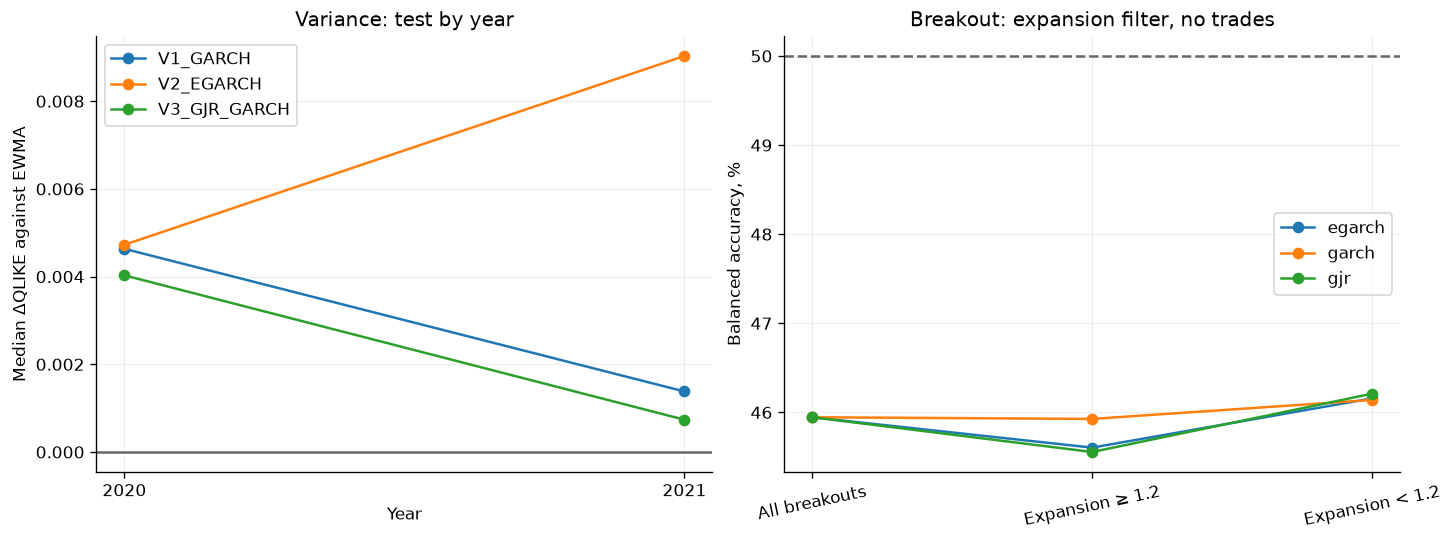

model,regime,files,n,balanced_accuracy
egarch,all_breakouts,46,63147,0.45946
egarch,expansion_ge_1.2,46,10533,0.45605
egarch,expansion_lt_1.2,46,52614,0.46158
garch,all_breakouts,46,63147,0.45946
garch,expansion_ge_1.2,46,13198,0.45927
garch,expansion_lt_1.2,46,49949,0.46140
gjr,all_breakouts,46,63147,0.45946
gjr,expansion_ge_1.2,46,13228,0.45556
gjr,expansion_lt_1.2,46,49919,0.46211


In [15]:
show(variance.query('period=="test" and horizon==5 and model in @VOLATILITY_NAMES').sort_values('qlike_delta_ewma',ascending=False)
    [['file','model','n','qlike_delta_ewma','volatility_correlation','floor_count','max_forecast']], "Largest ΔQLIKE against EWMA",12)
show(numerics.loc[(numerics.filter_guard_hits>0)|(numerics.next_guard_hits>0)|(numerics.nonfinite_forecasts>0)],"Numerical guard hits / undefined forecasts",15)
fig,axes=plt.subplots(1,2,figsize=(12,4.4),layout='constrained')
for name in VOLATILITY_NAMES:
    p=variance_summary.query('period in ["2020","2021"] and horizon==5 and model==@name').sort_values('period')
    axes[0].plot(p.period,p.median_qlike_delta_ewma,'o-',label=name)
axes[0].axhline(0,color='#666'); axes[0].set(title="Variance: test by year",ylabel="Median ΔQLIKE against EWMA",xlabel="Year"); axes[0].legend()
rs=regimes.groupby(['model','regime']).agg(files=('file','nunique'),n=('n','sum'),balanced_accuracy=('balanced_accuracy','mean')).reset_index()
for model,p in rs.groupby('model'):
    p=p.set_index('regime').reindex(['all_breakouts','expansion_ge_1.2','expansion_lt_1.2'])
    axes[1].plot(range(3),p.balanced_accuracy*100,'o-',label=model)
axes[1].set_xticks(range(3),["All breakouts",'Expansion ≥ 1.2','Expansion < 1.2'],rotation=12)
axes[1].axhline(50,color='#666',ls='--'); axes[1].set(ylabel='Balanced accuracy, %',title="Breakout: expansion filter, no trades"); axes[1].legend()
savefig(fig,'stability_and_expansion')
rs.to_csv(OUT/'breakout_expansion_summary.csv',index=False)
show(rs,"Breakout / expansion coverage",9)

## Loss-floor sensitivity

In [16]:
floor_rows=[]
for record in manifest['features']:
    if record['file'] not in set(coverage.loc[coverage.status.eq('eligible'),'file']): continue
    path=OUT/'forecasts'/(Path(record['file']).stem+'.parquet')
    if not path.exists(): continue
    data=pd.read_parquet(path)
    common=data.variance_common_h5.astype(bool).to_numpy()
    actual=data.loc[common,'variance_target_h5'].to_numpy()
    historical=data.loc[common,'variance_Historical_h5'].to_numpy()
    if not len(actual): continue
    for ratio in [1e-10,1e-8,1e-6]:
        floor=ratio*historical; ewma=np.maximum(data.loc[common,'variance_EWMA_h5'].to_numpy(),floor)
        base=np.log(ewma)+actual/ewma
        for model in ['Trailing30',*VOLATILITY_NAMES]:
            column=f'variance_{model}_h5'
            if column not in data: continue
            raw=data.loc[common,column].to_numpy(); pred=np.maximum(raw,floor)
            delta=np.mean(np.log(pred)+actual/pred-base)
            floor_rows.append(dict(file=record['file'],model=model,floor_ratio=ratio,n=len(actual),floor_count=int((raw<floor).sum()),qlike_delta_ewma=delta))
floor_sensitivity=pd.DataFrame(floor_rows)
floor_sensitivity.to_csv(OUT/'qlike_floor_sensitivity_by_file.csv',index=False)
reference=floor_sensitivity.query('floor_ratio==1e-8').merge(variance.query('period=="test" and horizon==5'),on=['file','model'],suffixes=('_sensitivity','_main'))
np.testing.assert_allclose(reference.qlike_delta_ewma_sensitivity,reference.qlike_delta_ewma_main,rtol=1e-10,atol=1e-12)
floor_summary=floor_sensitivity.groupby(['model','floor_ratio']).agg(files=('file','nunique'),median_delta=('qlike_delta_ewma','median'),mean_delta=('qlike_delta_ewma','mean'),floor_hits=('floor_count','sum')).reset_index()
floor_summary.to_csv(OUT/'qlike_floor_sensitivity_summary.csv',index=False)
show(floor_summary,"Same h5 test origins: scoring-floor sensitivity",12)


model,floor_ratio,files,median_delta,mean_delta,floor_hits
Trailing30,0.00000,53,356.24321,2303284.54261,1667
Trailing30,0.00000,53,3.55781,23032.84272,1667
Trailing30,0.00000,53,0.04151,230.33673,1667
V1_GARCH,0.00000,53,0.00218,0.01016,0
V1_GARCH,0.00000,53,0.00218,0.01016,0
V1_GARCH,0.00000,53,0.00218,0.01016,0
V2_EGARCH,0.00000,53,0.00816,0.03921,0
V2_EGARCH,0.00000,53,0.00816,0.03921,0
V2_EGARCH,0.00000,53,0.00816,0.03921,0
V3_GJR_GARCH,0.00000,53,0.00223,0.01018,0


## Summary

In [17]:
test_d=direction_summary.query('period=="test" and cohort=="common_all7"')
test_v=variance_summary.query('period=="test" and horizon==5 and model in @VOLATILITY_NAMES')
summary=dict(requested_files=54,standalone_eligible=int(coverage.status.eq('eligible').sum()),
    composite_common_files=int(coverage.common_direction_origins.fillna(0).gt(0).sum()),
    direction_common=test_d.to_dict('records'),variance_h5=test_v.to_dict('records'),backtest_run=False)
display(Markdown(f"""**All 54 files accounted for.** Standalone eligibility: {summary['standalone_eligible']}/54; """
    f"""the common cohort of all seven direction models contains {summary['composite_common_files']}/54 files. Insufficient history and fit failures remain explicit. """
    "Test forecasts use frozen training parameters. Fees, PnL and backtesting are outside this notebook."))
assert digest(INPUT)==input_hash
run=dict(input_manifest=str(INPUT.relative_to(ROOT)),input_sha256=input_hash,config=config,files=files,observed_end=manifest['observed_end'],
    train=['2016-01-01','2019-12-31'],test=['2020-01-01','2021-12-31'],inner_feature_fit=['2016-01-01','2018-12-31'],
    inner_direction_fit=['2019-01-01','2019-12-31'],test_refits=False,backtest_run=False,fees=None,costs=None,selection_is_retrospective=True,
    summary=summary,python=platform.python_version())
(OUT/'manifest.json').write_text(json.dumps(json_safe(run),ensure_ascii=False,indent=2)+'\n')
(OUT/'summary.json').write_text(json.dumps(json_safe(summary),ensure_ascii=False,indent=2)+'\n')
print("All results saved to",OUT.relative_to(ROOT))

**All 54 files accounted for.** Standalone eligibility: 53/54; the common cohort of all seven direction models contains 46/54 files. Insufficient history and fit failures remain explicit. Test forecasts use frozen training parameters. Fees, PnL and backtesting are outside this notebook.

All results saved to artifacts/research_54/models
